In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

from workload_data_loader import load_workload_instance

np.random.seed(42)  # each algorithm also creates its own generator from the run seed

n28, m28, u28, d28, b28 = load_workload_instance("multi_resource_n28_m2.txt")
n90, m90, u90, d90, b90 = load_workload_instance("multi_resource_n90_m5 (1).txt")

print("Instance 1: n =", n28, "| m =", m28, "| capacities =", b28)
print("Instance 2: n =", n90, "| m =", m90, "| capacities =", b90)
print("Total demand / capacity, Instance 1:", np.round(d28.sum(axis=1) / b28, 2))
print("Total demand / capacity, Instance 2:", np.round(d90.sum(axis=1) / b90, 2))

Instance 1: n = 28 | m = 2 | capacities = [500. 500.]
Instance 2: n = 90 | m = 5 | capacities = [2100. 1100. 3300. 3700. 3600.]
Total demand / capacity, Instance 1: [2.25 1.99]
Total demand / capacity, Instance 2: [1.58 3.06 1.17 1.05 1.1 ]


Every ratio is above 1, so not all models can be selected at the same time in either instance.

## Shared functions

A solution is stored as a binary vector `x`, where `x[j] = 1` means that model $j$ is selected. The functions below are used in all three parts.

Infeasible solutions are handled by a greedy repair. Each model is given an efficiency score, which is its utility divided by its resource use. Each resource is divided by its capacity first, so that resources with different scales can be added together. During repair, the selected model with the lowest efficiency is removed until all capacities are met. An optional fill step then adds unselected models, starting from the most efficient one, for as long as they still fit.

The cost of an algorithm is measured as the number of fitness evaluations, so the same budget can be given to every algorithm.

In [2]:
def calculate_utility(x, utilities):
    return float(utilities @ x)


def check_feasible(x, demands, capacities):
    return bool(np.all(demands @ x <= capacities))


def calculate_violation(x, demands, capacities):
    # amount over capacity, with each resource divided by its capacity (0 if feasible)
    excess = np.maximum(demands @ x - capacities, 0)
    return float((excess / capacities).sum())


def model_efficiency(utilities, demands, capacities):
    # utility per unit of resource use, after scaling each resource by its capacity
    normalised_cost = (demands / capacities[:, None]).sum(axis=0)
    return utilities / normalised_cost


def repair_solution(x, demands, capacities, efficiency, fill=True):
    x = x.copy()
    usage = demands @ x

    # step 1: remove the least efficient selected models until every capacity is met
    selected = np.where(x == 1)[0]
    for j in selected[np.argsort(efficiency[selected])]:
        if np.all(usage <= capacities):
            break
        x[j] = 0
        usage = usage - demands[:, j]

    # step 2 (optional): add the most efficient unselected models that still fit
    if fill:
        unselected = np.where(x == 0)[0]
        for j in unselected[np.argsort(-efficiency[unselected])]:
            if np.all(usage + demands[:, j] <= capacities):
                x[j] = 1
                usage = usage + demands[:, j]
    return x

## Part 1: Hill climber on Instance 1 (n = 28, m = 2)

A steepest-ascent hill climber with random restarts was implemented. The steps are:
1. A random binary vector is generated and repaired.
2. All one-bit-flip neighbours are generated in a random order. Each neighbour is repaired and evaluated.
3. The search moves to the best neighbour if it is better than the current solution.
4. If no neighbour is better (a local optimum), the search restarts from a new random solution.
5. The search stops after 3000 fitness evaluations.

Design choices:
- A one-bit flip was used as the neighbourhood operator, because adding or removing one model is the smallest possible change. With n = 28 there are only 28 neighbours, so the whole neighbourhood can be checked at every step.
- Every solution is repaired, so only feasible solutions are visited and every reported value is a valid selection.
- Random restarts were added because a plain hill climber stops at the first local optimum and would leave the rest of the budget unused.
- The fill step was switched off here. With fill on, a neighbour that removes a model could have the same model added back straight away, so many neighbours would be the same as the current solution.

In [3]:
def hill_climber(utilities, demands, capacities, max_evaluations=3000, seed=0):
    rng = np.random.default_rng(seed)
    n = len(utilities)
    efficiency = model_efficiency(utilities, demands, capacities)

    def random_start():
        x = rng.integers(0, 2, size=n)
        return repair_solution(x, demands, capacities, efficiency, fill=False)

    current = random_start()
    current_value = calculate_utility(current, utilities)
    best, best_value = current.copy(), current_value
    evaluations = 1
    history = [best_value]  # best-so-far utility after each evaluation

    while evaluations < max_evaluations:
        best_neighbour, best_neighbour_value = None, current_value

        # check every one-bit neighbour, in a random order
        for i in rng.permutation(n):
            if evaluations >= max_evaluations:
                break
            neighbour = current.copy()
            neighbour[i] = 1 - neighbour[i]
            neighbour = repair_solution(neighbour, demands, capacities, efficiency, fill=False)
            value = calculate_utility(neighbour, utilities)
            evaluations += 1
            if value > best_neighbour_value:
                best_neighbour, best_neighbour_value = neighbour, value
            if value > best_value:
                best, best_value = neighbour.copy(), value
            history.append(best_value)

        if best_neighbour is not None:
            current, current_value = best_neighbour, best_neighbour_value
        elif evaluations < max_evaluations:
            # local optimum: restart from a new random solution
            current = random_start()
            current_value = calculate_utility(current, utilities)
            evaluations += 1
            if current_value > best_value:
                best, best_value = current.copy(), current_value
            history.append(best_value)

    return best, best_value, history, evaluations

In [4]:
N_RUNS = 30
BUDGET_1 = 3000

part1_rows = []
part1_histories = []
for seed in range(N_RUNS):
    start = time.perf_counter()
    solution, value, history, evaluations = hill_climber(u28, d28, b28, BUDGET_1, seed)
    runtime = time.perf_counter() - start
    part1_rows.append({
        "seed": seed,
        "best_utility": value,
        "evaluations": evaluations,
        "runtime_s": runtime,
        "feasible": check_feasible(solution, d28, b28),
        "selected_models": int(solution.sum()),
    })
    part1_histories.append(history)

part1_results = pd.DataFrame(part1_rows)
display(part1_results[["best_utility", "runtime_s", "selected_models"]].describe().round(3))

best_found_1 = part1_results["best_utility"].max()
print("Feasibility rate:", 100 * part1_results["feasible"].mean(), "%")
print("Evaluations used in every run:", part1_results["evaluations"].unique())
print("Runs that reached the best value found (", best_found_1, "):",
      (part1_results["best_utility"] == best_found_1).sum(), "/", N_RUNS)

,best_utility,runtime_s,selected_models
count,30.000,30.000,30.000
mean,130523.000,0.085,11.100
std,382.349,0.014,0.845
min,129888.000,0.074,10.000
25%,130013.000,0.079,10.000
50%,130717.500,0.081,11.000
75%,130843.000,0.085,12.000
max,130883.000,0.146,12.000


Feasibility rate: 100.0 %
Evaluations used in every run: [3000]
Runs that reached the best value found ( 130883.0 ): 8 / 30


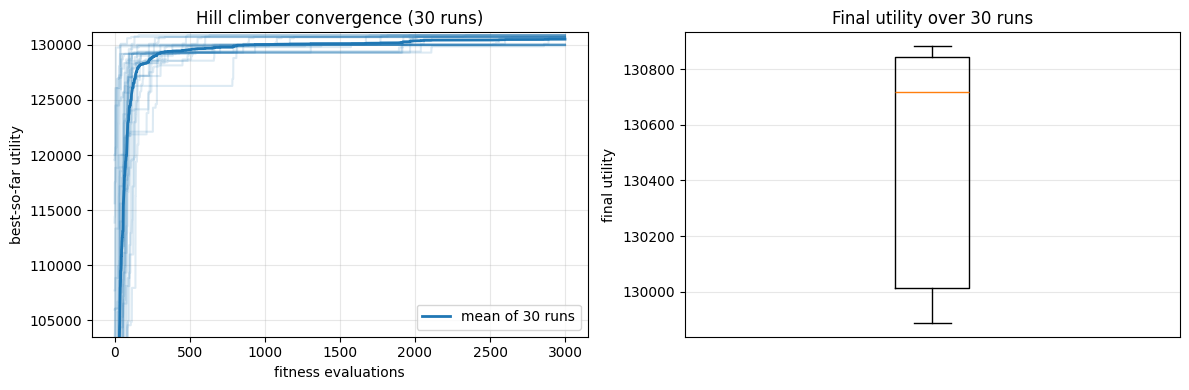

In [5]:
curves1 = np.array(part1_histories)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for curve in curves1:
    axes[0].plot(curve, color="tab:blue", alpha=0.15)
axes[0].plot(curves1.mean(axis=0), color="tab:blue", linewidth=2, label="mean of 30 runs")
axes[0].set_ylim(curves1[:, 100:].min() * 0.99, curves1.max() * 1.002)
axes[0].set_xlabel("fitness evaluations")
axes[0].set_ylabel("best-so-far utility")
axes[0].set_title("Hill climber convergence (30 runs)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].boxplot(part1_results["best_utility"])
axes[1].set_xticks([])
axes[1].set_ylabel("final utility")
axes[1].set_title("Final utility over 30 runs")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Results

All 30 runs ended with a feasible solution and used exactly 3000 evaluations. The mean final utility was 130,523 (standard deviation 382). The best value, 130,883, was reached in 8 of the 30 runs, and the worst run ended at 129,888, which is about 0.8% lower. Each run took less than 0.1 seconds on average.

From the convergence plot, most of the improvement happens in the first 300 or so evaluations. After that, the mean curve only rises in small steps, and these come from random restarts that land in a better area. The boxplot shows a wide gap between the lower quartile (about 130,000) and the median (about 130,700). This suggests that the runs tend to end in one of two groups of local optima, and a single bit flip is not enough to move from the lower group to the higher one. This is mainly why Part 2 uses a population-based method with crossover.

## Part 2: Genetic algorithm on Instance 2 (n = 90, m = 5)

A genetic algorithm (GA) was chosen for the larger instance. A population of solutions is kept, and new solutions are made by combining two parents. Crossover can combine good groups of models from different solutions, which a one-bit hill climber has no way of doing.

The GA follows the cycle: initialise, evaluate, select parents, crossover, mutate, repair, replace.

- Representation: a binary chromosome of length 90, where gene $j$ shows whether model $j$ is selected.
- Initial population: 60 random vectors, each repaired so that the population is feasible from the start.
- Selection: tournament selection with k = 3. No fitness scaling is needed, and k = 3 gives a moderate selection pressure, so diversity is not lost too quickly.
- Crossover: uniform crossover with probability 0.9. The order of the models in the data file has no meaning, so there is no reason to keep neighbouring genes together as one-point crossover would.
- Mutation: bit flip with rate 1/n, which gives about one flipped gene per child. This keeps some exploration while leaving most of a good child unchanged.
- Constraint handling: greedy repair with the fill step. With five constraints, crossover and mutation often create children that go over a capacity. Repair turns these into feasible solutions close to the child, and the fill step uses up any spare capacity.
- Replacement: each generation is replaced by new children, except that the 2 best individuals are copied over (elitism), so the best solution is never lost.
- Budget: 10,000 fitness evaluations per run (about 166 generations).

The same function also has a penalty option, which is used in Part 3. This means the two variants in Part 3 differ only in how the constraints are handled.

In [6]:
def tournament_selection(population, fitness, rng, k=3):
    contestants = rng.choice(len(population), size=k, replace=False)
    return population[contestants[np.argmax(fitness[contestants])]]


def uniform_crossover(parent1, parent2, rng):
    mask = rng.random(len(parent1)) < 0.5
    return np.where(mask, parent1, parent2)


def bit_flip_mutation(x, rate, rng):
    child = x.copy()
    flip = rng.random(len(x)) < rate
    child[flip] = 1 - child[flip]
    return child


def genetic_algorithm(utilities, demands, capacities, constraint_handling="repair",
                      population_size=60, max_evaluations=10000, crossover_rate=0.9,
                      tournament_size=3, n_elite=2, seed=0):
    # constraint_handling = "repair":  every child is repaired, fitness = utility
    # constraint_handling = "penalty": children are kept as they are, fitness = utility - penalty
    rng = np.random.default_rng(seed)
    n = len(utilities)
    mutation_rate = 1 / n
    efficiency = model_efficiency(utilities, demands, capacities)
    penalty_weight = efficiency.max()

    best_solution = np.zeros(n, dtype=int)
    best_value = 0.0
    feasible_count = 0
    history = []  # best feasible utility so far, after each evaluation

    def evaluate(x):
        nonlocal best_solution, best_value, feasible_count
        value = calculate_utility(x, utilities)
        violation = calculate_violation(x, demands, capacities)
        if violation == 0:
            feasible_count += 1
            if value > best_value:
                best_solution, best_value = x.copy(), value
        history.append(best_value)
        if constraint_handling == "penalty":
            return value - penalty_weight * violation
        return value

    population = rng.integers(0, 2, size=(population_size, n))
    if constraint_handling == "repair":
        population = np.array([repair_solution(x, demands, capacities, efficiency) for x in population])
    fitness = np.array([evaluate(x) for x in population])
    evaluations = population_size

    while evaluations < max_evaluations:
        # elitism: the best individuals go straight into the next generation
        elite = np.argsort(-fitness)[:n_elite]
        new_population = [population[i].copy() for i in elite]
        new_fitness = [fitness[i] for i in elite]

        while len(new_population) < population_size and evaluations < max_evaluations:
            parent1 = tournament_selection(population, fitness, rng, tournament_size)
            parent2 = tournament_selection(population, fitness, rng, tournament_size)
            if rng.random() < crossover_rate:
                child = uniform_crossover(parent1, parent2, rng)
            else:
                child = parent1.copy()
            child = bit_flip_mutation(child, mutation_rate, rng)
            if constraint_handling == "repair":
                child = repair_solution(child, demands, capacities, efficiency)
            new_population.append(child)
            new_fitness.append(evaluate(child))
            evaluations += 1

        population = np.array(new_population)
        fitness = np.array(new_fitness)

    return best_solution, best_value, history, feasible_count / evaluations

In [7]:
BUDGET_2 = 10000


def run_ga_experiment(constraint_handling, seeds=range(N_RUNS), budget=BUDGET_2):
    rows, histories, solutions = [], [], []
    for seed in seeds:
        start = time.perf_counter()
        solution, value, history, feasible_share = genetic_algorithm(
            u90, d90, b90, constraint_handling, max_evaluations=budget, seed=seed)
        rows.append({
            "seed": seed,
            "best_utility": value,
            "evaluations": len(history),
            "runtime_s": time.perf_counter() - start,
            "feasible": check_feasible(solution, d90, b90),
            "selected_models": int(solution.sum()),
            "feasible_share": feasible_share,
        })
        histories.append(history)
        solutions.append(solution)
    return pd.DataFrame(rows), histories, solutions


part2_results, part2_histories, part2_solutions = run_ga_experiment("repair")

display(part2_results[["best_utility", "runtime_s", "selected_models"]].describe().round(3))
print("Feasibility rate:", 100 * part2_results["feasible"].mean(), "%")
print("Evaluations used in every run:", part2_results["evaluations"].unique())

,best_utility,runtime_s,selected_models
count,30.000,30.000,30.000
mean,11189.633,4.110,50.667
std,2.297,0.157,0.547
min,11182.000,3.849,49.000
25%,11187.000,4.001,50.000
50%,11191.000,4.076,51.000
75%,11191.000,4.175,51.000
max,11191.000,4.636,51.000


Feasibility rate: 100.0 %
Evaluations used in every run: [10000]


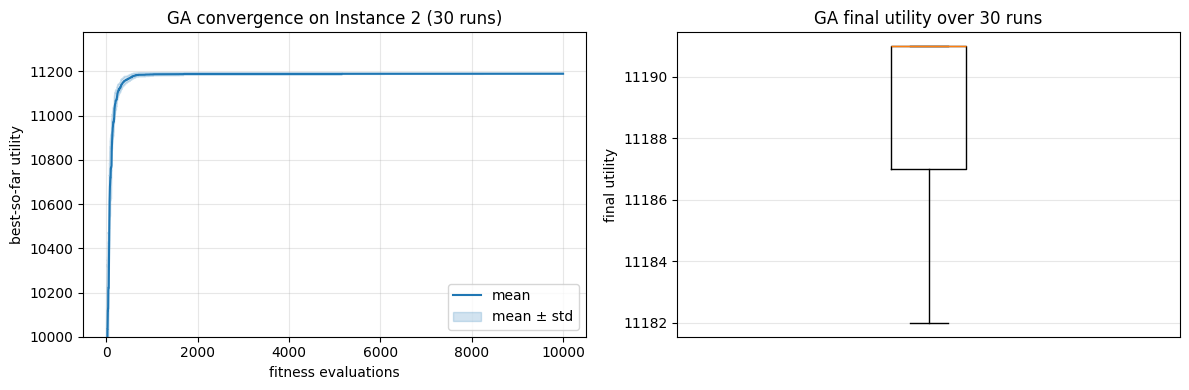

Best utility: 11191.0 | seed: 0 | models selected: 51


,resource,used,capacity,within_capacity
0,Resource 1,1777.0,2100.0,True
1,Resource 2,1100.0,1100.0,True
2,Resource 3,2259.0,3300.0,True
3,Resource 4,2232.0,3700.0,True
4,Resource 5,2418.0,3600.0,True


In [8]:
curves2 = np.array(part2_histories)
mean2, std2 = curves2.mean(axis=0), curves2.std(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(mean2, color="tab:blue", label="mean")
axes[0].fill_between(range(BUDGET_2), mean2 - std2, mean2 + std2, color="tab:blue", alpha=0.2, label="mean ± std")
axes[0].set_ylim(10000, None)
axes[0].set_xlabel("fitness evaluations")
axes[0].set_ylabel("best-so-far utility")
axes[0].set_title("GA convergence on Instance 2 (30 runs)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].boxplot(part2_results["best_utility"])
axes[1].set_xticks([])
axes[1].set_ylabel("final utility")
axes[1].set_title("GA final utility over 30 runs")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

best_run = part2_results["best_utility"].idxmax()
best_solution = part2_solutions[best_run]
audit = pd.DataFrame({
    "resource": [f"Resource {i + 1}" for i in range(m90)],
    "used": d90 @ best_solution,
    "capacity": b90,
})
audit["within_capacity"] = audit["used"] <= audit["capacity"]
print("Best utility:", part2_results["best_utility"].max(), "| seed:", part2_results["seed"][best_run],
      "| models selected:", int(best_solution.sum()))
display(audit)

### Results

The GA found a feasible solution in every run. The mean final utility was 11,189.6 with a standard deviation of only 2.3, and the worst run reached 11,182. The best value, 11,191, was reached in more than half of the runs (the median is 11,191). It may be the optimum for this instance, but this cannot be confirmed because the exact optimum was not computed.

The convergence curve rises quickly and levels off at around 1,500 evaluations. The band around the mean is narrow, so the runs behaved very similarly. The resource check of the best solution shows that Resource 2 is used up exactly (1100 / 1100), while the other resources still have spare capacity. This is expected, since Resource 2 is the most over-subscribed resource (total demand is 3.06 times its capacity). Each run took about 4 seconds, and most of this time was spent in the repair function.

## Part 3: Repair vs penalty constraint handling

**Question.** On Instance 2, which constraint-handling method makes better use of a fixed number of fitness evaluations? Instance 2 is tightly constrained, since the total demand is between 1.05 and 3.06 times the capacity of each resource.

**Variants.** All other settings were kept the same (population 60, tournament k = 3, uniform crossover 0.9, mutation 1/n, 2 elites, 10,000 evaluations, same seeds).
- Variant A (repair): every child is repaired before it is evaluated, so every evaluated solution is feasible. This is the GA from Part 2.
- Variant B (penalty): children are evaluated as they are, with fitness $f(\mathbf{x}) - \lambda V(\mathbf{x})$. Here $V$ is the total amount over capacity (each resource divided by its capacity) and $\lambda$ is the highest model efficiency. This value was chosen so that going over a capacity should not be rewarded. The result of each run is the best feasible solution that was found.

**Hypothesis (H1).** Variant A reaches a higher final utility than Variant B under the same budget. Repair uses knowledge about the problem (the efficiency scores) to turn every child into a good feasible solution. The penalty GA spends part of its budget on infeasible solutions, and the best feasible solutions lie close to the capacity limits, where the penalised fitness gives little guidance.

**Protocol.** 30 paired runs were carried out, with the same seed used for A and B. The final utilities were compared with a two-sided Wilcoxon signed-rank test at α = 0.05. This test was chosen because the results are paired and there is no reason to assume that they are normally distributed. H0: the paired differences are centred on zero.

In [9]:
results_A, histories_A = part2_results, part2_histories  # Variant A is the Part 2 GA
results_B, histories_B, _ = run_ga_experiment("penalty")

assert (results_A["evaluations"] == BUDGET_2).all() and (results_B["evaluations"] == BUDGET_2).all()

summary3 = pd.DataFrame({
    "A: repair": results_A[["best_utility", "feasible_share", "runtime_s"]].mean(),
    "B: penalty": results_B[["best_utility", "feasible_share", "runtime_s"]].mean(),
}).T
summary3["std_utility"] = [results_A["best_utility"].std(), results_B["best_utility"].std()]
summary3["best"] = [results_A["best_utility"].max(), results_B["best_utility"].max()]
summary3["worst"] = [results_A["best_utility"].min(), results_B["best_utility"].min()]
display(summary3.round(3))

,best_utility,feasible_share,runtime_s,std_utility,best,worst
A: repair,11189.633,1.000,4.110,2.297,11191.0,11182.0
B: penalty,11155.067,0.558,0.852,40.236,11191.0,10966.0


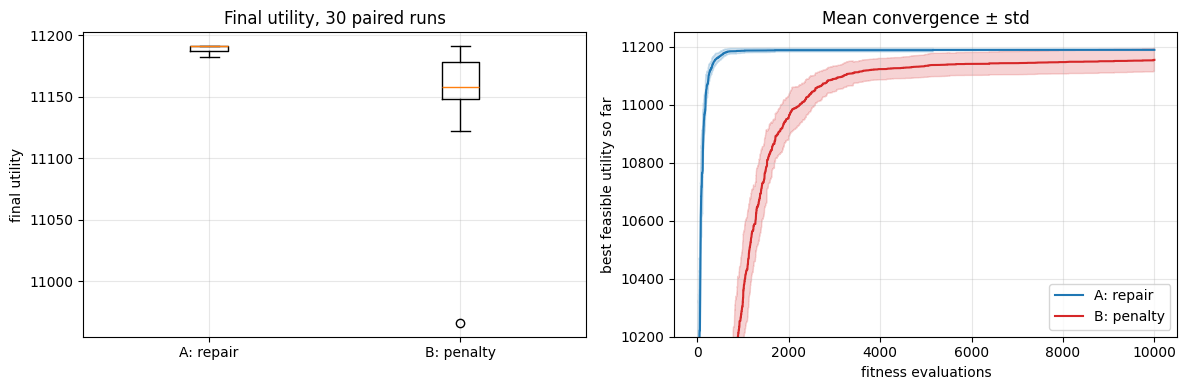

In [10]:
curves_A, curves_B = np.array(histories_A), np.array(histories_B)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].boxplot([results_A["best_utility"], results_B["best_utility"]], tick_labels=["A: repair", "B: penalty"])
axes[0].set_ylabel("final utility")
axes[0].set_title("Final utility, 30 paired runs")
axes[0].grid(alpha=0.3)

for curves, label, colour in [(curves_A, "A: repair", "tab:blue"), (curves_B, "B: penalty", "tab:red")]:
    mean, std = curves.mean(axis=0), curves.std(axis=0)
    axes[1].plot(mean, color=colour, label=label)
    axes[1].fill_between(range(BUDGET_2), mean - std, mean + std, color=colour, alpha=0.2)
axes[1].set_ylim(10200, 11250)
axes[1].set_xlabel("fitness evaluations")
axes[1].set_ylabel("best feasible utility so far")
axes[1].set_title("Mean convergence ± std")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
utility_A = results_A.sort_values("seed")["best_utility"].to_numpy()
utility_B = results_B.sort_values("seed")["best_utility"].to_numpy()
difference = utility_A - utility_B

print("Paired differences (A - B): mean", round(difference.mean(), 2), "| median", np.median(difference))
print("A better in", (difference > 0).sum(), "| equal in", (difference == 0).sum(),
      "| B better in", (difference < 0).sum(), "of", len(difference), "pairs")

if np.allclose(difference, 0):
    print("All paired differences are zero, so the Wilcoxon test is not informative.")
else:
    statistic, p_value = wilcoxon(utility_A, utility_B, alternative="two-sided")
    print(f"Wilcoxon signed-rank test: W = {statistic}, p = {p_value:.3g}")
    print("Decision at alpha = 0.05:", "reject H0" if p_value < 0.05 else "H0 cannot be rejected")

runtime_A, runtime_B = results_A["runtime_s"].mean(), results_B["runtime_s"].mean()
print(f"Mean runtime: repair {runtime_A:.2f} s/run, penalty {runtime_B:.2f} s/run (ratio {runtime_A / runtime_B:.1f})")

Paired differences (A - B): mean 34.57 | median 33.0
A better in 28 | equal in 1 | B better in 1 of 30 pairs
Wilcoxon signed-rank test: W = 3.0, p = 3.46e-06
Decision at alpha = 0.05: reject H0
Mean runtime: repair 4.11 s/run, penalty 0.85 s/run (ratio 4.8)


### Results and discussion

H1 is supported. The repair GA reached a mean utility of 11,189.6, compared with 11,155.1 for the penalty GA. Variant A was better in 28 of the 30 pairs, equal in 1 and worse in 1. The Wilcoxon test gave W = 3 and p = 3.5 × 10⁻⁶, so H0 is rejected at α = 0.05. The penalty GA was also much less consistent (standard deviation 40.2 against 2.3), and it had one weak run that ended at 10,966.

The convergence plot helps to explain the gap. The repair GA has a good feasible solution after only a few hundred evaluations, while the penalty GA improves much more slowly. Only about 56% of the penalty GA's evaluations were spent on feasible solutions, compared with 100% for the repair GA, so a large part of its budget did not produce a usable selection.

There are trade-offs between the two methods. Repair gave higher and more consistent utility under the same evaluation budget, and it keeps every solution feasible, but it needs a problem-specific heuristic (the efficiency ordering). The penalty method is simpler and more general, and it allows the search to pass through infeasible regions, although its result depends on the choice of λ.

Execution time also differs. Repair was about 5 times slower per run (around 4 s against 0.8 s on this machine) because of the drop and fill loops. If both methods were given the same wall-clock time instead of the same number of evaluations, the penalty GA could carry out about 5 times as many evaluations, and the gap would probably be smaller. This was not tested, since the experiment was designed around an equal number of fitness evaluations.